# LAB 07 — Transformer Architecture
From attention to Transformer: Embedding → Positional Encoding → [Multi-Head Self-Attention → Add & Norm → FFN → Add & Norm] × N → Pooling → Classifier.

- **Core implementation:** `transformer_block.py` (MultiHeadSelfAttention, FeedForward, TransformerBlock, TransformerClassifier tự ghép từ Linear / softmax / LayerNorm / Dropout; không dùng `nn.TransformerEncoderLayer`) và `positional_encoding.py` (sinusoidal PE).
- **Dữ liệu:** IMDb, split 60/20/20 stratified seed 2026 giống LAB 04–06 (train 29,746 / val 9,916 / test 9,916); vocabulary 20,000 (chỉ từ train).
- Các model được huấn luyện trên **Kaggle (GPU)**, kết quả lưu trong `cache/`; chạy lại notebook ở local sẽ nạp cache (xóa `cache/` để train lại).

In [1]:
import sys, os, time, csv, json, random, math, warnings
from collections import Counter
sys.path.insert(0, "../lab04")                       # dùng lại preprocessing của LAB 04 (cùng split)
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import preprocessing as pp
import transformer_block as tb
from transformer_block import MultiHeadSelfAttention, TransformerBlock, TransformerClassifier
from positional_encoding import sinusoidal_pe, plot_pe
import positional_encoding as pe_mod
warnings.filterwarnings("ignore")
SEED = 2026
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
np.set_printoptions(precision=4, suppress=True)
RESULTS = []
def log(exp, cfg, metric, val): RESULTS.append((exp, cfg, metric, val))
os.makedirs("cache", exist_ok=True)

## Kiểm tra phần tính tay (mục 6, 10, 14, 18)

In [2]:
pe_mod._tests(); tb._tests()
X = np.array([[1,0,1,0],[0,1,0,1],[1,1,0,0]], float)
WQ = np.array([[1,0],[0,1],[1,0],[0,0]], float); WK = np.array([[1,0],[0,1],[0,0],[0,1]], float); WV = np.array([[1,0],[0,1],[1,0],[0,2]], float)
Q, K, V = X @ WQ, X @ WK, X @ WV; S = Q @ K.T / np.sqrt(2)
A = np.exp(S - S.max(1, keepdims=True)); A /= A.sum(1, keepdims=True)
print("Mục 6  Q =", Q.tolist(), "| K =", K.tolist(), "| V =", V.tolist()); print("A =\n", A); print("Z = AV =\n", A @ V)
print("Mục 10 PE(pos=0,1,2; d=4) =\n", sinusoidal_pe(3, 4))
x = np.array([1., 2.]); h = np.maximum(0, np.eye(2) @ x + np.array([0., -1.])); y = np.array([[1,1],[1,-1]]) @ h + np.array([0., 1.])
print("Mục 14 h = ReLU(W1x+b1) =", h, "| y = W2h+b2 =", y)
shapes = {}; TransformerBlock(128, 4, 512, 0.0).eval()(torch.randn(8, 100, 128), shapes=shapes)
display(pd.DataFrame({"shape": {k: " × ".join(map(str, v)) for k, v in shapes.items()}}).rename_axis("Mục 18 (B=8, T=100, d_model=128, h=4, d_ff=512)"))
mha = MultiHeadSelfAttention(128, 4); print("tham số multi-head attention (d_model=128):", sum(p.numel() for p in mha.parameters()))
log("calc", "bai6", "Z_row1", ",".join(f"{t:.3f}" for t in (A @ V)[0])); log("calc", "bai10", "PE_pos1", ",".join(f"{t:.4f}" for t in sinusoidal_pe(3, 4)[1]))
log("calc", "bai14", "y", ",".join(f"{t:g}" for t in y))

positional encoding tests passed


transformer block tests passed (shape, khớp nn.TransformerEncoderLayer, permutation equivariance)
Mục 6  Q = [[2.0, 0.0], [0.0, 1.0], [1.0, 1.0]] | K = [[1.0, 0.0], [0.0, 2.0], [1.0, 1.0]] | V = [[2.0, 0.0], [0.0, 3.0], [1.0, 1.0]]
A =
 [[0.4458 0.1084 0.4458]
 [0.14   0.576  0.284 ]
 [0.1978 0.4011 0.4011]]
Z = AV =
 [[1.3374 0.771 ]
 [0.5641 2.0119]
 [0.7967 1.6044]]
Mục 10 PE(pos=0,1,2; d=4) =
 [[ 0.      1.      0.      1.    ]
 [ 0.8415  0.5403  0.01    1.    ]
 [ 0.9093 -0.4161  0.02    0.9998]]
Mục 14 h = ReLU(W1x+b1) = [1. 1.] | y = W2h+b2 = [2. 1.]


,shape
"Mục 18 (B=8, T=100, d_model=128, h=4, d_ff=512)",
X,8 × 100 × 128
Q,8 × 4 × 100 × 32
K,8 × 4 × 100 × 32
V,8 × 4 × 100 × 32
Attention scores,8 × 4 × 100 × 100
Attention weights,8 × 4 × 100 × 100
Heads output,8 × 4 × 100 × 32
Concat,8 × 100 × 128
Attention output (sau W^O),8 × 100 × 128


tham số multi-head attention (d_model=128): 66048


## 11. Experiment 1 — Positional encoding
(a) Heatmap sinusoidal PE (T = 64, d = 128). (b) Câu ["I", "love", "NLP"] với embedding ngẫu nhiên (d = 8) qua **một Transformer block khởi tạo ngẫu nhiên** (chưa train, d_model = 8, 2 head); so sánh representation của từng token khi đổi thứ tự thành "NLP love I", **không** và **có** positional encoding.

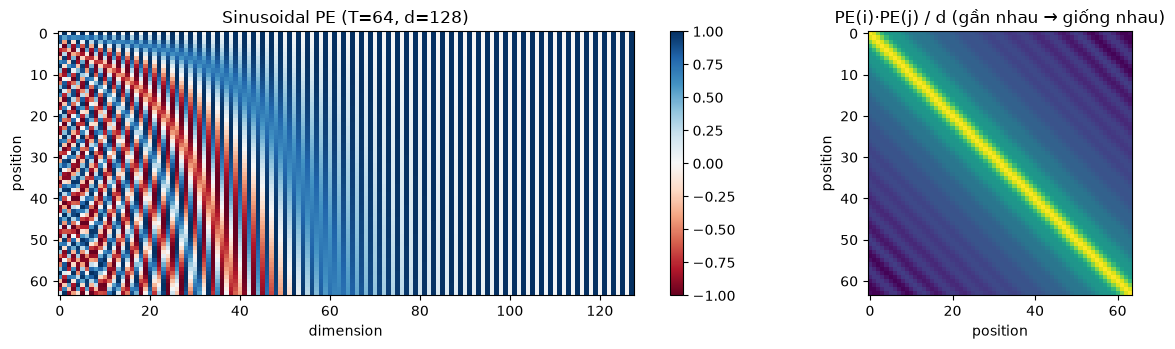

vị trí trong S1/S2  ‖h(S1) − h(S2)‖
positional token                                                 
không PE   I                                 0/2           0.0000
           love                              1/1           0.0000
           NLP                               2/0           0.0000
           (mean pooling câu)                              0.0000
có PE      I                                 0/2           2.0428
           love                              1/1           0.0533
           NLP                               2/0           1.3156
           (mean pooling câu)                              0.2711

In [3]:
plot_pe(64, 128, "positional_encoding.png"); plt.show()
torch.manual_seed(SEED)
vocab3 = {"I": 0, "love": 1, "NLP": 2}; E = torch.randn(3, 8)
blk8 = TransformerBlock(8, 2, 16, dropout=0.0).eval(); PE8 = torch.tensor(sinusoidal_pe(3, 8), dtype=torch.float32)
@torch.no_grad()
def rep(tokens, use_pe):
    x = E[[vocab3[t] for t in tokens]][None]
    if use_pe: x = x + PE8[None]
    return blk8(x)[0][0]
s1, s2 = ["I", "love", "NLP"], ["NLP", "love", "I"]
rows = []
for use_pe in (False, True):
    r1, r2 = rep(s1, use_pe), rep(s2, use_pe)
    for t in s1:
        rows.append(dict(positional=("có PE" if use_pe else "không PE"), token=t,
                         **{"vị trí trong S1/S2": f"{s1.index(t)}/{s2.index(t)}", "‖h(S1) − h(S2)‖": round(float((r1[s1.index(t)] - r2[s2.index(t)]).norm()), 4)}))
    rows.append(dict(positional=("có PE" if use_pe else "không PE"), token="(mean pooling câu)", **{"vị trí trong S1/S2": "", "‖h(S1) − h(S2)‖": round(float((r1.mean(0) - r2.mean(0)).norm()), 4)}))
t1 = pd.DataFrame(rows).set_index(["positional", "token"]); display(t1)
for (p, t), r in t1.iterrows(): log("exp1_positional", f"{p}|{t}", "dist_S1_S2", r["‖h(S1) − h(S2)‖"])

**Nhận xét Experiment 1:** heatmap cho thấy mỗi vị trí có một vector PE riêng; các chiều đầu dao động nhanh, chiều sau dao động chậm, và hai vị trí gần nhau có PE giống nhau hơn hai vị trí xa nhau. **Không PE**: representation của mỗi token giống hệt nhau (khoảng cách 0) dù "I" ở vị trí 0 hay 2, nên "I love NLP" và "NLP love I" chỉ là cùng một tập vector bị đổi chỗ và vector câu (mean pooling) trùng nhau. **Có PE**: cùng token ở vị trí khác nhau cho representation khác nhau, vector câu cũng khác (trừ "love" vẫn ở vị trí 1 nhưng vẫn đổi vì nhìn thấy các token khác ở vị trí khác).

**Tại sao thứ tự là vấn đề nếu chỉ có self-attention?** Score qᵢᵀkⱼ chỉ phụ thuộc **nội dung** hai token, không phụ thuộc i, j; softmax và tổng có trọng số AV không quan tâm thứ tự các hàng. Hoán vị input chỉ hoán vị output (permutation equivariant), nên model không phân biệt được ai đứng trước.

## Dữ liệu, vocabulary và các model
Vocabulary 20,000: `<pad>` = 0, `<unk>` = 1, `<cls>` = 2 (chỉ dùng cho CLS pooling) + 19,997 từ phổ biến nhất của train. Mặc định giữ **256** token đầu, pad bên phải.

Cùng điều kiện cho mọi model: embedding / d_model **128**, Adam lr 1e-3, batch 64, 8 epoch, dropout 0.1, gradient clipping 1.0, chọn epoch có validation loss thấp nhất.
- **LSTM**: embedding 128 → LSTM hidden 128 → hidden state cuối → linear.
- **Transformer** (`T_h4`): embedding 128 (× √128) + sinusoidal PE → 2 TransformerBlock (4 head, d_ff 256) → mean pooling (bỏ PAD) → linear.
- Biến thể: số head 1/2/4/8 (`T_h*`), max_length 32/64/128/256 (`T_h4_L*`), CLS pooling (`T_cls`), bỏ positional encoding (`T_nope`).

In [4]:
data = pp.prepare(pp.load_imdb())
train, val, test = (d.reset_index(drop=True) for d in pp.split(data))
cnt = Counter(w for t in train.text for w in pp.tokenize(t))
itos = ["<pad>", "<unk>", "<cls>"] + [w for w, c in cnt.most_common() if c >= 3][:19997]
stoi = {w: i for i, w in enumerate(itos)}
print("train/val/test:", len(train), len(val), len(test), "| vocabulary:", len(itos))
def encode(texts, L, cls=False):
    rows, lens = [], []
    for t in texts:
        ids = [stoi.get(w, 1) for w in pp.tokenize(t)]
        ids = ([2] + ids[:L-1]) if cls else (ids[:L] or [1])
        lens.append(len(ids)); rows.append(ids + [0]*(L-len(ids)))
    return torch.tensor(rows), torch.tensor(lens)
EPOCHS, BATCH, LR, D = 8, 64, 1e-3, 128
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("device:", DEVICE)
class LSTMClassifier(nn.Module):
    def __init__(self, vocab, emb=D, hid=128, drop=0.1):
        super().__init__()
        self.emb = nn.Embedding(vocab, emb, padding_idx=0); self.rnn = nn.LSTM(emb, hid, batch_first=True)
        self.drop, self.fc = nn.Dropout(drop), nn.Linear(hid, 1)
    def forward(self, x, lens, return_attn=False):
        p = nn.utils.rnn.pack_padded_sequence(self.emb(x), lens.cpu(), batch_first=True, enforce_sorted=False)
        _, (h, _) = self.rnn(p); return self.fc(self.drop(h[-1])).squeeze(-1)
SPECS = {"LSTM": dict(kind="lstm", L=256)}
for h_ in (1, 2, 4, 8): SPECS[f"T_h{h_}"] = dict(kind="tf", L=256, heads=h_, pooling="mean", pe=True)
for L_ in (32, 64, 128): SPECS[f"T_h4_L{L_}"] = dict(kind="tf", L=L_, heads=4, pooling="mean", pe=True)
SPECS["T_cls"] = dict(kind="tf", L=256, heads=4, pooling="cls", pe=True)
SPECS["T_nope"] = dict(kind="tf", L=256, heads=4, pooling="mean", pe=False)
def build(name):
    s = SPECS[name]
    if s["kind"] == "lstm": return LSTMClassifier(len(itos))
    return TransformerClassifier(len(itos), d_model=D, n_heads=s["heads"], d_ff=256, n_layers=2, max_len=512, dropout=0.1, use_pe=s["pe"], pooling=s["pooling"])
def enc(name, texts): s = SPECS[name]; return encode(texts, s["L"], cls=s.get("pooling") == "cls")
def n_params(m): return sum(p.numel() for p in m.parameters())
lossf = nn.BCEWithLogitsLoss()
@torch.no_grad()
def predict(model, X, lens, bs=256):
    model.eval(); dev = next(model.parameters()).device; out = []
    for i in range(0, len(X), bs): out.append(torch.sigmoid(model(X[i:i+bs].to(dev), lens[i:i+bs])).cpu())
    return torch.cat(out).numpy()
def metrics(y, p, thr=0.5):
    q = (p >= thr).astype(int)
    return dict(accuracy=accuracy_score(y, q), precision=precision_score(y, q), recall=recall_score(y, q), f1=f1_score(y, q))
def train_run(name, epochs=EPOCHS):
    path = f"cache/{name}.pt"
    if os.path.exists(path): return torch.load(path, map_location="cpu", weights_only=False)
    torch.manual_seed(SEED); np.random.seed(SEED)
    Xtr, ltr = enc(name, train.text); Xva, lva = enc(name, val.text); Xte, lte = enc(name, test.text)
    Xtr = Xtr.to(DEVICE); ytr = torch.tensor(train.label.values, dtype=torch.float32, device=DEVICE); yva = val.label.values
    model = build(name).to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=LR)
    if DEVICE.type == "cuda": torch.cuda.reset_peak_memory_stats()
    hist = dict(train_loss=[], val_loss=[], val_acc=[], epoch_s=[]); best = (1e9, None, 0); t_total = 0.0
    for ep in range(epochs):
        model.train(); t0 = time.time(); perm = torch.randperm(len(Xtr)); tl = 0.0
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i+BATCH]; idd = idx.to(DEVICE)
            loss = lossf(model(Xtr[idd], ltr[idx]), ytr[idd])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); tl += loss.item() * len(idx)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        dt = time.time() - t0; t_total += dt
        pv = predict(model, Xva, lva)
        vl = float(lossf(torch.logit(torch.tensor(pv).clamp(1e-6, 1-1e-6)), torch.tensor(yva, dtype=torch.float32)))
        hist["train_loss"].append(tl/len(Xtr)); hist["val_loss"].append(vl); hist["val_acc"].append(float(((pv>=.5)==yva).mean())); hist["epoch_s"].append(dt)
        if vl < best[0]: best = (vl, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}, ep + 1)
        print(f"{name} ep{ep+1}: train {tl/len(Xtr):.4f} val {vl:.4f} val_acc {hist['val_acc'][-1]:.3f} {dt:.1f}s")
    model.load_state_dict(best[1]); pt = predict(model, Xte, lte)
    res = dict(name=name, spec=SPECS[name], hist=hist, best_epoch=best[2], epochs=epochs, train_time=t_total, params=n_params(model), device=str(DEVICE),
               peak_mem_mb=(torch.cuda.max_memory_allocated()/1e6 if DEVICE.type == "cuda" else float("nan")),
               test_probs=pt, test_metrics=metrics(test.label.values, pt), state=best[1])
    torch.save(res, path); return res
def load(name):
    m = build(name); m.load_state_dict(runs[name]["state"]); return m.eval()

train/val/test: 29746 9916 9916 | vocabulary: 20000
device: cpu


In [5]:
runs = {n: train_run(n) for n in SPECS}
print("thiết bị huấn luyện:", runs["T_h4"]["device"])

thiết bị huấn luyện: cuda


## 21. Experiment 4 — Transformer vs LSTM (max_length 256, test set)

In [6]:
def row(n): r = runs[n]; m = r["test_metrics"]; return dict(Model=n, Parameters=r["params"], Training_time_s=round(r["train_time"], 1),
                                                     Accuracy=round(m["accuracy"], 4), Precision=round(m["precision"], 4), Recall=round(m["recall"], 4), F1=round(m["f1"], 4), Best_epoch=r["best_epoch"])
tab4 = pd.DataFrame([row("LSTM"), row("T_h4")]).set_index("Model").rename(index={"T_h4": "Transformer (T_h4)"}); display(tab4)
for n in ("LSTM", "T_h4"):
    for k, v in runs[n]["test_metrics"].items(): log("exp4_lstm_vs_transformer", n, k, round(v, 4))
    log("exp4_lstm_vs_transformer", n, "params", runs[n]["params"]); log("exp4_lstm_vs_transformer", n, "train_time_s", round(runs[n]["train_time"], 1))
emb_params = len(itos) * D
print(f"tham số embedding: {emb_params:,} | phần còn lại: LSTM {runs['LSTM']['params']-emb_params:,}, Transformer {runs['T_h4']['params']-emb_params:,}")
print("thời gian / epoch (s): LSTM", np.round(runs["LSTM"]["hist"]["epoch_s"], 1), "| Transformer", np.round(runs["T_h4"]["hist"]["epoch_s"], 1))

,Parameters,Training_time_s,Accuracy,Precision,Recall,F1,Best_epoch
Model,,,,,,,
LSTM,2692225,50.9,0.8747,0.8856,0.8618,0.8735,5
Transformer (T_h4),2825089,134.1,0.8672,0.8773,0.8549,0.8660,8


tham số embedding: 2,560,000 | phần còn lại: LSTM 132,225, Transformer 265,089
thời gian / epoch (s): LSTM [7.3 6.2 6.3 6.2 6.2 6.2 6.2 6.2] | Transformer [16.8 16.9 16.8 16.7 16.7 16.7 16.7 16.7]


**Nhận xét Experiment 4:**
- LSTM nhỉnh hơn Transformer một chút (F1 0.874 so với 0.866, accuracy 0.875 so với 0.867); chênh lệch nhỏ, Transformer không thắng.
- Transformer có nhiều tham số hơn ở phần không phải embedding (265k so với 132k; 2 block, mỗi block có W^Q, W^K, W^V, W^O và FFN), nhưng embedding 2.56M chiếm phần lớn ở cả hai model.
- Thời gian train **Transformer chậm hơn** (16.7 s/epoch so với 6.2 s/epoch). Lý do: LSTM dùng kernel cuDNN tối ưu; Transformer ở đây tự viết (không dùng kernel attention hợp nhất), mỗi batch phải tạo 2 layer × 4 head ma trận 256 × 256 cho 64 câu, nên dù tính song song theo vị trí vẫn tốn hơn ở độ dài này.
- **Khác biệt performance có thể đến từ:** (1) LSTM mang **thứ tự sẵn có** (đọc tuần tự), Transformer chỉ biết thứ tự qua sinusoidal PE cộng vào embedding; (2) **pooling**: LSTM dùng hidden state cuối, Transformer dùng mean pooling nên mọi token đóng góp như nhau sau khi trộn; (3) **tối ưu**: Transformer vẫn đang giảm val loss ở epoch 8 (chưa hội tụ) còn LSTM đã overfit từ epoch 5; (4) Transformer học từ đầu với 30k review, chưa có pretraining.

## 29. Learning curves

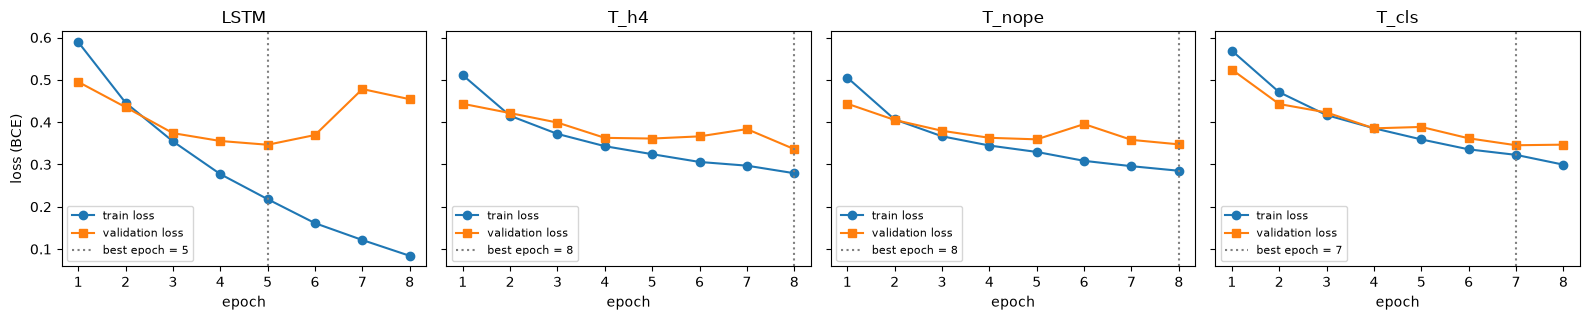

,LSTM,T_h4,T_nope,T_cls
epoch (train / val loss),,,,
1,0.589 / 0.495,0.511 / 0.443,0.505 / 0.443,0.569 / 0.524
2,0.446 / 0.435,0.415 / 0.421,0.406 / 0.405,0.471 / 0.443
3,0.355 / 0.374,0.372 / 0.399,0.367 / 0.380,0.417 / 0.423
4,0.277 / 0.355,0.343 / 0.363,0.345 / 0.363,0.386 / 0.385
5,0.218 / 0.347,0.324 / 0.361,0.330 / 0.359,0.359 / 0.389
6,0.161 / 0.370,0.306 / 0.366,0.309 / 0.395,0.336 / 0.362
7,0.121 / 0.478,0.297 / 0.384,0.296 / 0.358,0.323 / 0.345
8,0.084 / 0.454,0.279 / 0.336,0.285 / 0.347,0.299 / 0.347


In [7]:
show = ["LSTM", "T_h4", "T_nope", "T_cls"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.3), sharey=True)
for ax, n in zip(axes, show):
    r = runs[n]; e = range(1, len(r["hist"]["train_loss"]) + 1)
    ax.plot(e, r["hist"]["train_loss"], "o-", label="train loss"); ax.plot(e, r["hist"]["val_loss"], "s-", label="validation loss")
    ax.axvline(r["best_epoch"], color="gray", ls=":", label=f"best epoch = {r['best_epoch']}"); ax.set_title(n); ax.set_xlabel("epoch"); ax.legend(fontsize=8)
axes[0].set_ylabel("loss (BCE)"); plt.tight_layout(); plt.savefig("learning_curves.png", dpi=130); plt.show()
display(pd.DataFrame({n: [f"{a:.3f} / {b:.3f}" for a, b in zip(runs[n]["hist"]["train_loss"], runs[n]["hist"]["val_loss"])] for n in show},
                     index=pd.Index(range(1, EPOCHS + 1), name="epoch (train / val loss)")))

**Nhận xét learning curves:**
- **LSTM overfit:** train loss giảm đều 0.59 → 0.08 nhưng val loss thấp nhất ở epoch 5 (0.347) rồi tăng lên 0.45–0.48. Chọn epoch 5.
- **Transformer chưa overfit rõ, có dao động (instability nhẹ):** train loss giảm chậm (0.51 → 0.28); val loss đi xuống nhưng lên xuống (0.361 → 0.366 → 0.384 → 0.336), thấp nhất ở epoch 8 → có thể train thêm được (gần underfitting/chưa hội tụ trong 8 epoch).
- T_nope và T_cls có dạng đường cong tương tự T_h4.

## Evaluation — confusion matrix

LSTM  TN=4385 FP=554 FN=688 TP=4289
T_h4  TN=4344 FP=595 FN=722 TP=4255


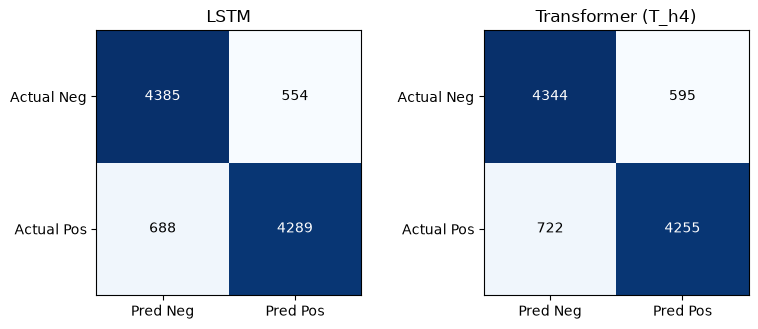

In [8]:
y = test.label.values
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
for ax, n in zip(axes, ("LSTM", "T_h4")):
    cm = confusion_matrix(y, (runs[n]["test_probs"] >= .5).astype(int)); ax.imshow(cm, cmap="Blues"); ax.set_title("Transformer (T_h4)" if n == "T_h4" else n)
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xticklabels(["Pred Neg", "Pred Pos"]); ax.set_yticklabels(["Actual Neg", "Actual Pos"])
    for i in range(2):
        for j in range(2): ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
    tn, fp, fn, tp = cm.ravel(); log("confusion", n, "TN_FP_FN_TP", f"{tn},{fp},{fn},{tp}"); print(f"{n:5s} TN={tn} FP={fp} FN={fn} TP={tp}")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=130); plt.show()

## 12. Permutation experiment — "dog bites man" vs "man bites dog"
**A:** Transformer đã huấn luyện **không PE** (`T_nope`). **B:** Transformer **có PE** (`T_h4`). So sánh vector câu (mean pooling của output block cuối) và P(positive) của S1, S2. Kiểm chứng thêm trên 1,000 review test: xáo trộn ngẫu nhiên thứ tự từ rồi đo prediction thay đổi bao nhiêu.

In [9]:
tfA, tfB, lstm = load("T_nope"), load("T_h4"), load("LSTM")
@torch.no_grad()
def sent_vec(model, text, L=256):
    X, l = encode([text], L); logit, attns, H = model(X, l, return_attn=True); n = int(l[0])
    return H[0, :n].mean(0), float(torch.sigmoid(logit)[0]), H[0, :n]
rows = []
for name, m in (("A: không PE (T_nope)", tfA), ("B: có PE (T_h4)", tfB)):
    v1, p1, H1 = sent_vec(m, "dog bites man"); v2, p2, H2 = sent_vec(m, "man bites dog")
    rows.append(dict(Experiment=name, P_pos_S1=round(p1, 6), P_pos_S2=round(p2, 6), **{"‖v(S1) − v(S2)‖": round(float((v1 - v2).norm()), 6),
                     "cos(v(S1), v(S2))": round(float(torch.cosine_similarity(v1, v2, 0)), 6),
                     "token 'dog': ‖h(S1) − h(S2)‖": round(float((H1[0] - H2[2]).norm()), 6)}))
tp = pd.DataFrame(rows).set_index("Experiment"); display(tp)
for e, r in tp.iterrows(): log("exp_permutation", e, "dist_S1_S2|P1|P2", f"{r['‖v(S1) − v(S2)‖']}|{r['P_pos_S1']}|{r['P_pos_S2']}")
rng = np.random.RandomState(SEED); idx = rng.choice(len(test), 1000, replace=False)
orig = [test.text[i] for i in idx]; shuf = [" ".join(rng.permutation(pp.tokenize(t)[:256])) for t in orig]; yy = y[idx]
rows = []
for name, m, L in (("LSTM", lstm, 256), ("T_nope", tfA, 256), ("T_h4", tfB, 256)):
    Xo, lo = encode(orig, L); Xs, ls = encode(shuf, L); po, ps = predict(m, Xo, lo), predict(m, Xs, ls)
    rows.append(dict(Model=name, acc_original=round(((po>=.5)==yy).mean(), 4), acc_shuffled=round(((ps>=.5)==yy).mean(), 4),
                     pct_prediction_changed=round(((po>=.5)!=(ps>=.5)).mean()*100, 2), mean_abs_dP=round(float(np.abs(po-ps).mean()), 5)))
    log("exp_permutation_shuffle", name, "acc_orig|acc_shuf|pct_changed", f"{rows[-1]['acc_original']}|{rows[-1]['acc_shuffled']}|{rows[-1]['pct_prediction_changed']}")
tsh = pd.DataFrame(rows).set_index("Model"); display(tsh)

,P_pos_S1,P_pos_S2,‖v(S1) − v(S2)‖,"cos(v(S1), v(S2))",token 'dog': ‖h(S1) − h(S2)‖
Experiment,,,,,
A: không PE (T_nope),0.999745,0.999745,0.000001,1.000000,0.000001
B: có PE (T_h4),0.941331,0.944480,0.150315,0.999701,0.433793


,acc_original,acc_shuffled,pct_prediction_changed,mean_abs_dP
Model,,,,
LSTM,0.886,0.855,11.7,0.12433
T_nope,0.863,0.863,0.0,0.00000
T_h4,0.868,0.872,1.2,0.01636


**Nhận xét permutation experiment (bằng chứng thực nghiệm):**
- **A (không PE):** "dog bites man" và "man bites dog" cho vector câu **trùng nhau** (khoảng cách ≈ 10⁻⁶, chỉ là sai số số học) và cùng P(positive) = 0.999745; vector của token "dog" cũng giống hệt dù ở vị trí 0 hay 2. Model **không phân biệt** được hai câu.
- **B (có PE):** vector câu khác nhau (khoảng cách 0.150), vector "dog" khác nhau (0.434), P(positive) 0.9413 so với 0.9445.
- Trên 1,000 review test với từ bị **xáo trộn ngẫu nhiên**: T_nope cho prediction **giống hệt** (0% thay đổi, |ΔP| = 0); T_h4 chỉ đổi 1.2% prediction; LSTM đổi 11.7% và accuracy giảm 0.886 → 0.855.
- Kết luận: positional information là thành phần **cần thiết** để Transformer phân biệt thứ tự. Nhưng trên IMDb sentiment, mất thứ tự chỉ làm giảm accuracy rất ít (T_nope F1 0.863 so với T_h4 0.866); Transformer có PE vẫn chủ yếu dựa vào **từ nào xuất hiện** hơn là thứ tự.

## 19. Experiment 2 — Number of attention heads (d_model = 128, max_length 256)

In [10]:
rows = []
for h_ in (1, 2, 4, 8):
    r = runs[f"T_h{h_}"]; m = r["test_metrics"]
    rows.append(dict(Heads=h_, d_k=D // h_, Parameters=r["params"], Training_time_s=round(r["train_time"], 1), Accuracy=round(m["accuracy"], 4), F1=round(m["f1"], 4),
                     min_val_loss=round(min(r["hist"]["val_loss"]), 4), Best_epoch=r["best_epoch"]))
    for k in ("Accuracy", "F1", "Training_time_s", "Parameters"): log("exp2_heads", f"h={h_}", k, rows[-1][k])
t2 = pd.DataFrame(rows).set_index("Heads"); display(t2)

,d_k,Parameters,Training_time_s,Accuracy,F1,min_val_loss,Best_epoch
Heads,,,,,,,
1,128,2825089,83.2,0.8656,0.8681,0.3509,7
2,64,2825089,102.0,0.8641,0.8671,0.3367,8
4,32,2825089,134.1,0.8672,0.8660,0.3361,8
8,16,2825089,200.6,0.8538,0.8527,0.3469,4


**Nhận xét Experiment 2:**
- Số tham số **giống hệt** nhau (2,825,089) với 1, 2, 4, 8 head: W^Q, W^K, W^V, W^O luôn là 128 × 128, chỉ chia thành nhiều phần nhỏ hơn.
- F1: 0.868 / 0.867 / 0.866 / 0.853; chênh lệch giữa 1–4 head chỉ ~0.002, còn 8 head (d_k = 16) kém hơn. Tăng số head **không** làm accuracy tăng.
- Thời gian train **tăng** theo số head (83 → 102 → 134 → 201 s): mỗi head tạo một ma trận T × T riêng, nên 8 head có 8 attention matrix 256 × 256 cho mỗi câu.
- **Tăng số head có tăng representation dimension không?** Không; d_model cố định 128. **Khi d_model cố định, tăng head thì d_k = 128 / h giảm** (128 → 64 → 32 → 16): mỗi head nhìn một không gian con nhỏ hơn.

## 20. Experiment 3 — Attention head diversity (model T_h4)
(a) Attention matrix của 4 head ở layer 1 và layer 2 cho một câu. (b) Định lượng trên 300 review test: entropy chuẩn hóa (0 = tập trung vào một token, 1 = đều), max weight trung bình, khoảng cách trung bình |i − j| mà head nhìn tới, tỉ lệ attention vào chính nó (đường chéo), và độ giống nhau giữa các head (cosine của các hàng attention).

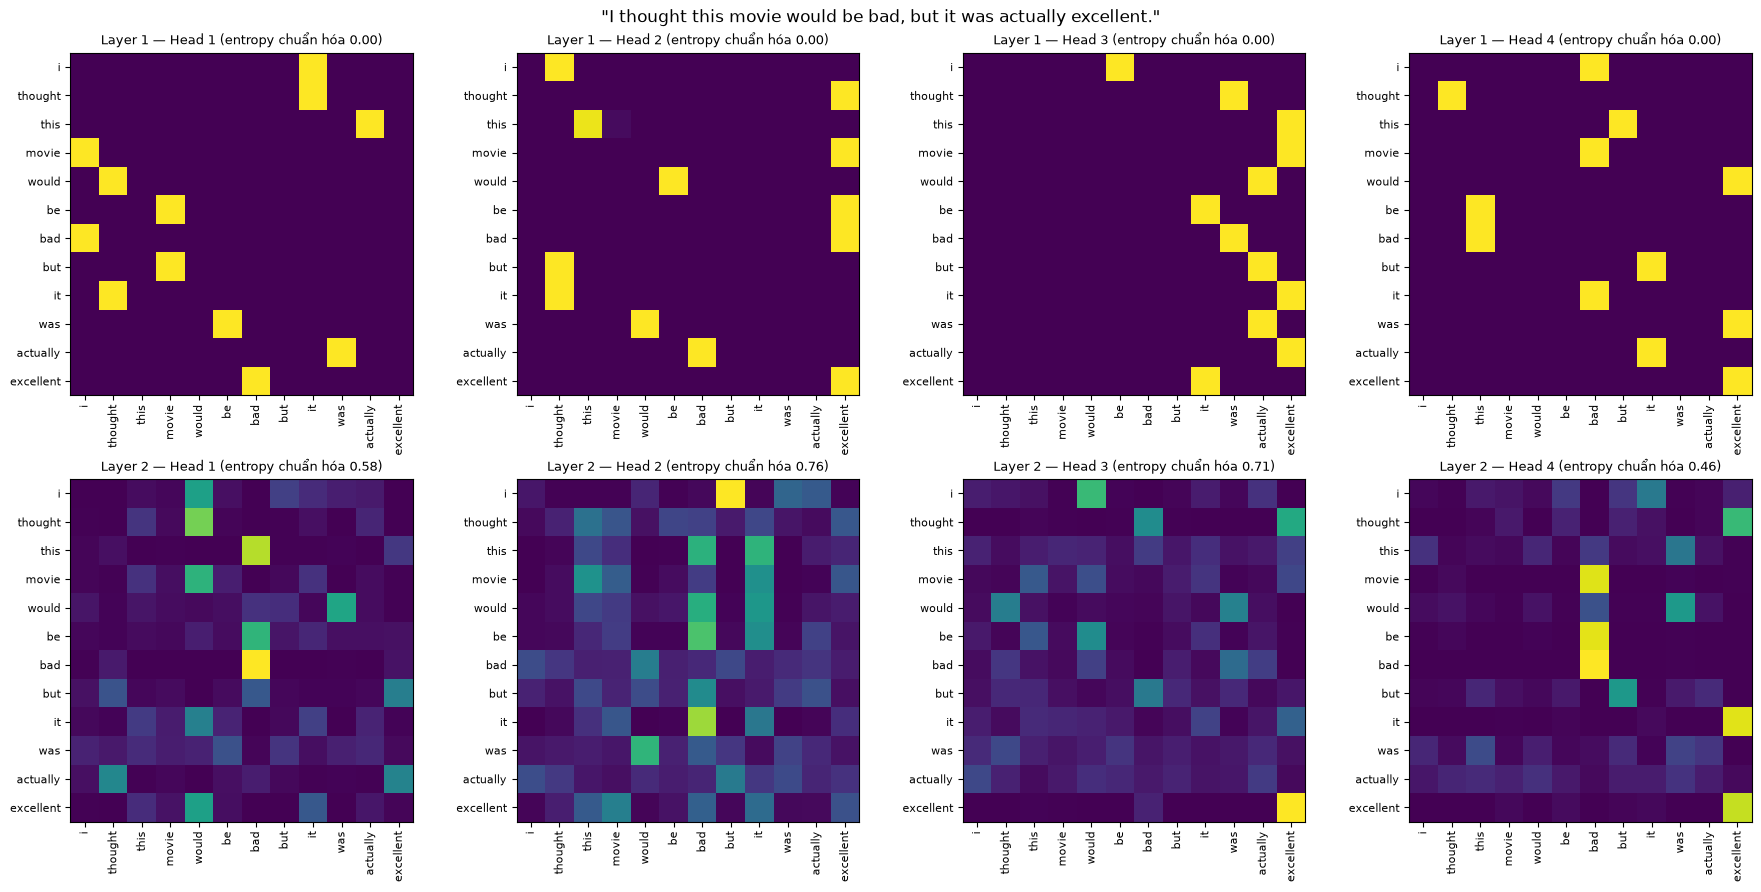

entropy_norm  max_weight  mean_distance  self_attention
layer head                                                         
1     1            0.014       0.971           60.0           0.009
      2            0.018       0.963           59.8           0.006
      3            0.017       0.966           61.3           0.005
      4            0.017       0.964           60.1           0.012
2     1            0.706       0.222           60.1           0.008
      2            0.710       0.213           60.6           0.006
      3            0.769       0.168           60.2           0.006
      4            0.655       0.231           59.7           0.013

Layer 1: cosine giữa các head (trung bình 300 review)


,H1,H2,H3,H4
H1,1.000,0.014,0.006,0.012
H2,0.014,1.000,0.010,0.018
H3,0.006,0.010,1.000,0.010
H4,0.012,0.018,0.010,1.000


Layer 2: cosine giữa các head (trung bình 300 review)


,H1,H2,H3,H4
H1,1.000,0.066,0.080,0.143
H2,0.066,1.000,0.155,0.060
H3,0.080,0.155,1.000,0.139
H4,0.143,0.060,0.139,1.000


In [11]:
@torch.no_grad()
def attn_maps(model, text, L=256):
    X, l = encode([text], L); logit, attns, H = model(X, l, return_attn=True); n = int(l[0])
    return pp.tokenize(text)[:n], [A[0, :, :n, :n].numpy() for A in attns], float(torch.sigmoid(logit)[0])
demo = "I thought this movie would be bad, but it was actually excellent."
tk, maps, _ = attn_maps(tfB, demo)
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for li in range(2):
    for hi in range(4):
        ax = axes[li, hi]; M = maps[li][hi]; ax.imshow(M, cmap="viridis", vmin=0)
        ax.set_xticks(range(len(tk))); ax.set_xticklabels(tk, rotation=90, fontsize=8); ax.set_yticks(range(len(tk))); ax.set_yticklabels(tk, fontsize=8)
        ent = (-(M * np.log(M + 1e-12)).sum(1) / np.log(len(tk))).mean()
        ax.set_title(f"Layer {li+1} — Head {hi+1} (entropy chuẩn hóa {ent:.2f})", fontsize=9)
plt.suptitle(f"\"{demo}\""); plt.tight_layout(); plt.savefig("attention_heads.png", dpi=110); plt.show()
rng = np.random.RandomState(SEED); sample = rng.choice(len(test), 300, replace=False)
stats = {(li, hi): dict(ent=[], mx=[], dist=[], diag=[]) for li in range(2) for hi in range(4)}; sims = {li: [] for li in range(2)}
for i in sample:
    _, maps, _ = attn_maps(tfB, test.text[i]); n = maps[0].shape[-1]; pos = np.arange(n)
    for li in range(2):
        for hi in range(4):
            M = maps[li][hi]; s = stats[(li, hi)]
            s["ent"].append((-(M * np.log(M + 1e-12)).sum(1) / np.log(n)).mean()); s["mx"].append(M.max(1).mean())
            s["dist"].append((M * np.abs(pos[:, None] - pos[None])).sum(1).mean()); s["diag"].append(np.diag(M).mean())
        F = maps[li].reshape(4, -1); F = F / np.linalg.norm(F, axis=1, keepdims=True); sims[li].append(F @ F.T)
rows = []
for (li, hi), s in stats.items():
    rows.append(dict(layer=li+1, head=hi+1, entropy_norm=round(np.mean(s["ent"]), 3), max_weight=round(np.mean(s["mx"]), 3),
                     mean_distance=round(np.mean(s["dist"]), 1), self_attention=round(np.mean(s["diag"]), 3)))
    log("exp3_heads", f"L{li+1}H{hi+1}", "entropy|max_weight|distance", f"{rows[-1]['entropy_norm']}|{rows[-1]['max_weight']}|{rows[-1]['mean_distance']}")
t3 = pd.DataFrame(rows).set_index(["layer", "head"]); display(t3)
for li in range(2):
    Sm = np.mean(sims[li], axis=0); print(f"Layer {li+1}: cosine giữa các head (trung bình 300 review)"); display(pd.DataFrame(Sm, index=[f"H{h+1}" for h in range(4)], columns=[f"H{h+1}" for h in range(4)]).round(3))

**Nhận xét Experiment 3 (mô tả, không đặt tên "syntax/semantics" cho head):**
- **Layer 1: cả 4 head tập trung cực mạnh** (entropy chuẩn hóa ≈ 0.01–0.02, max weight ≈ 0.96–0.97): mỗi query gần như chỉ nhìn **một** token. Giả thuyết: embedding được nhân √128 nên score QKᵀ rất lớn và softmax bão hòa (giống quan sát về scaling ở LAB 06).
- **Layer 2: phân tán hơn nhiều** (entropy 0.66–0.77, max weight 0.17–0.23). Head 4 tập trung nhất, head 3 phân tán nhất.
- **Các head khác nhau:** cosine giữa các head ở layer 1 chỉ 0.006–0.018 (gần như chọn token khác nhau hoàn toàn), ở layer 2 là 0.06–0.16. **Không có head nào redundant** (không cặp nào có cosine gần 1).
- Mọi head đều nhìn xa trung bình ~60 token (không phải pattern cục bộ/đường chéo; tỉ lệ attention vào chính nó < 0.02).
- Trong câu demo, ở layer 2 head 1, 2, 4 có nhiều query nhìn vào "bad" và head 2, 4 nhìn vào "excellent", tức các từ mang sentiment; nhưng đây là quan sát phân phối attention, không chứng minh head "hiểu" cấu trúc tương phản.
- **Multi-head có thực sự tạo pattern khác nhau không?** Có, trong experiment này các head có attention pattern khác nhau rõ rệt (định lượng bằng cosine thấp), dù accuracy không tăng khi thêm head.

## 22. Experiment 5 — Sequence length (Transformer 4 head)
Tokens retained = % token của test set được giữ lại. Attention memory = phần tử của attention matrix × 4 byte (float32) cho **một batch 64 × 4 head × 1 layer**; peak GPU memory đo thật khi train.

,Tokens_retained_pct,Reviews_fully_kept_pct,T2,Attention_memory_MB,Peak_GPU_MB,Training_time_s,Accuracy,F1
Length,,,,,,,,
32,13.9,0.3,1024,1.05,114,28.1,0.7247,0.7136
64,27.4,5.4,4096,4.19,189,28.6,0.7831,0.7920
128,51.6,26.8,16384,16.78,414,54.7,0.8320,0.8347
256,76.9,71.5,65536,67.11,1166,134.1,0.8672,0.8660


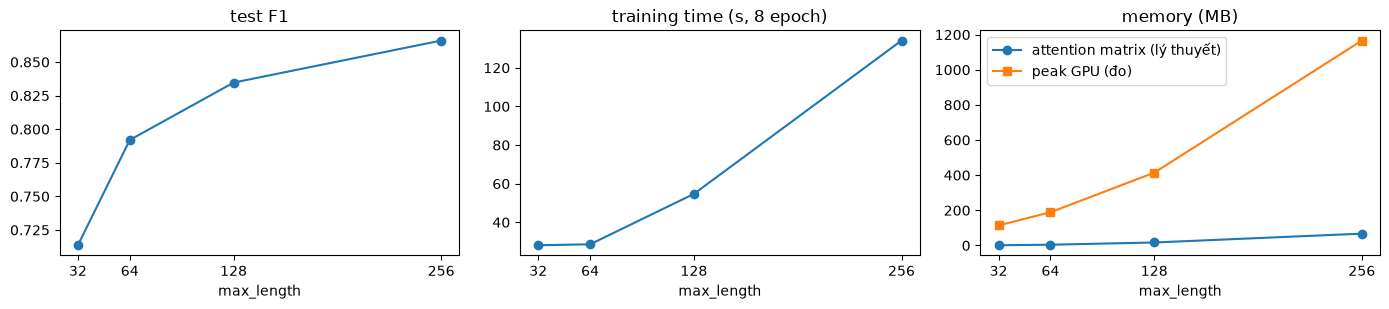

In [12]:
tok_len = np.array([len(pp.tokenize(t)) for t in test.text]); rows = []
for L_, n in ((32, "T_h4_L32"), (64, "T_h4_L64"), (128, "T_h4_L128"), (256, "T_h4")):
    r = runs[n]
    rows.append(dict(Length=L_, Tokens_retained_pct=round(np.minimum(tok_len, L_).sum() / tok_len.sum() * 100, 1), Reviews_fully_kept_pct=round((tok_len <= L_).mean()*100, 1),
                     T2=L_*L_, Attention_memory_MB=round(64*4*L_*L_*4/1e6, 2), Peak_GPU_MB=(round(r["peak_mem_mb"]) if r["peak_mem_mb"] == r["peak_mem_mb"] else np.nan), Training_time_s=round(r["train_time"], 1),
                     Accuracy=round(r["test_metrics"]["accuracy"], 4), F1=round(r["test_metrics"]["f1"], 4)))
    for k in ("Tokens_retained_pct", "Attention_memory_MB", "Training_time_s", "F1"): log("exp5_length", f"L={L_}", k, rows[-1][k])
t5 = pd.DataFrame(rows).set_index("Length"); display(t5)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
ax[0].plot(t5.index, t5.F1, "o-"); ax[0].set_title("test F1"); ax[1].plot(t5.index, t5.Training_time_s, "o-"); ax[1].set_title("training time (s, 8 epoch)")
ax[2].plot(t5.index, t5.Attention_memory_MB, "o-", label="attention matrix (lý thuyết)"); ax[2].plot(t5.index, t5.Peak_GPU_MB, "s-", label="peak GPU (đo)"); ax[2].set_title("memory (MB)"); ax[2].legend()
for a in ax: a.set_xlabel("max_length"); a.set_xticks(t5.index)
plt.tight_layout(); plt.show()

**Nhận xét Experiment 5:**
- Giữ nhiều token hơn thì F1 tăng mạnh: 32 token (13.9% token) F1 0.714 → 256 token (76.9%) F1 0.866. Review IMDb dài nên truncation mất nhiều thông tin.
- Chi phí tăng nhanh: T² tăng 64 lần (1,024 → 65,536), attention memory lý thuyết 1 → 67 MB / layer / batch, peak GPU đo được 114 → 1,166 MB, thời gian train 28 → 134 s. Từ 128 → 256: T² ×4, peak memory ×2.8, thời gian ×2.5.
- **Vì sao không đơn giản tăng sequence length?** Lợi ích giảm dần (128 → 256 chỉ +0.03 F1) còn chi phí attention tăng theo T²; với review dài nghìn token, bộ nhớ và thời gian tăng nhanh hơn nhiều so với lợi ích. Cần cách khác (truncation thông minh, chia đoạn, attention hiệu quả hơn).

### Prediction 6 — Transformer có luôn nhanh hơn LSTM? (đo thời gian forward + backward một batch 8 câu)
Đo trên GPU Kaggle (nạp từ `cache/timing_cuda.json`); nếu chưa có thì đo trên thiết bị hiện tại.

In [13]:
def bench(device, lengths, B=8, reps=3):
    out = []
    lstm_b = LSTMClassifier(len(itos)).to(device); tf_b = TransformerClassifier(len(itos), D, 4, 256, 2, max_len=max(lengths), dropout=0.0).to(device)
    for L_ in lengths:
        x = torch.randint(3, len(itos), (B, L_), device=device); l = torch.full((B,), L_); yb = torch.zeros(B, device=device); r = dict(T=L_)
        for name, m in (("LSTM", lstm_b), ("Transformer", tf_b)):
            try:
                for k in range(reps + 1):
                    if k == 1:
                        if device.type == "cuda": torch.cuda.synchronize()
                        t0 = time.perf_counter()
                    loss = lossf(m(x, l), yb); m.zero_grad(); loss.backward()
                if device.type == "cuda": torch.cuda.synchronize()
                r[f"{name}_ms"] = round((time.perf_counter() - t0) / reps * 1000, 1)
            except RuntimeError:                                  # hết bộ nhớ
                r[f"{name}_ms"] = float("nan")
                if device.type == "cuda": torch.cuda.empty_cache()
        out.append(r)
    return out
path_t = "cache/timing_cuda.json"
if os.path.exists(path_t): timing, tdev = json.load(open(path_t)), "cuda (Kaggle)"
elif DEVICE.type == "cuda": timing, tdev = bench(DEVICE, [32, 128, 512, 1024, 2048, 4096]), "cuda"; json.dump(timing, open(path_t, "w"))
else: timing, tdev = bench(DEVICE, [32, 128, 512, 1024]), "cpu"
tt = pd.DataFrame(timing).set_index("T"); tt["Transformer / LSTM"] = (tt.Transformer_ms / tt.LSTM_ms).round(2)
print("thiết bị:", tdev); display(tt)
for T_, r in tt.iterrows(): log("pred6_timing", f"T={T_}|{tdev}", "LSTM_ms|Transformer_ms", f"{r.LSTM_ms}|{r.Transformer_ms}")

thiết bị: cuda (Kaggle)


,LSTM_ms,Transformer_ms,Transformer / LSTM
T,,,
32,3.3,5.5,1.67
128,6.7,5.6,0.84
512,20.6,12.1,0.59
1024,38.0,41.4,1.09
2048,75.1,146.9,1.96
4096,151.2,571.6,3.78


**Nhận xét (Prediction 6):** đo forward + backward một batch 8 câu trên GPU Kaggle: Transformer **nhanh hơn** LSTM ở T = 128 và 512 (0.84 và 0.59 lần), nhưng **chậm hơn** ở T = 32 (chi phí cố định) và từ T = 1024 trở lên (1.09 → 1.96 → 3.78 lần ở T = 4096). Thời gian LSTM tăng gần tuyến tính (×2 mỗi khi T ×2), Transformer tăng nhanh hơn (×3.9 từ 2048 → 4096) do O(T²). Transformer **không** luôn nhanh hơn RNN.

## 25. Experiment 6 — Pooling strategy (Transformer 4 head, max_length 256)
CLS-style: thêm token `<cls>` ở vị trí 0 (nên chỉ còn 255 token review) và dùng output của vị trí đó; mean pooling: trung bình output của mọi token thật.

In [14]:
rows = []
for n, lab_ in (("T_h4", "Mean"), ("T_cls", "CLS-style")):
    r = runs[n]; m = r["test_metrics"]
    rows.append(dict(Pooling=lab_, Accuracy=round(m["accuracy"], 4), F1=round(m["f1"], 4), Training_time_s=round(r["train_time"], 1), min_val_loss=round(min(r["hist"]["val_loss"]), 4), Best_epoch=r["best_epoch"]))
    for k in ("Accuracy", "F1", "Training_time_s"): log("exp6_pooling", lab_, k, rows[-1][k])
t6 = pd.DataFrame(rows).set_index("Pooling"); display(t6)
r = runs["T_nope"]["test_metrics"]; print(f"(thêm) bỏ positional encoding T_nope: accuracy {r['accuracy']:.4f}, F1 {r['f1']:.4f}")
for k, v in r.items(): log("exp_no_pe", "T_nope", k, round(v, 4))

,Accuracy,F1,Training_time_s,min_val_loss,Best_epoch
Pooling,,,,,
Mean,0.8672,0.8660,134.1,0.3361,8
CLS-style,0.8629,0.8615,132.2,0.3454,7


(thêm) bỏ positional encoding T_nope: accuracy 0.8598, F1 0.8632


**Nhận xét Experiment 6:** mean pooling hơi tốt hơn CLS-style (F1 0.866 so với 0.862, val loss 0.336 so với 0.345), thời gian gần như nhau. Cách lấy representation **có ảnh hưởng nhưng nhỏ** ở đây. CLS phải học cách gom thông tin vào một vị trí qua attention (và mất 1 token cho `<cls>`), còn mean pooling lấy trực tiếp trung bình mọi token; khi train từ đầu với ít dữ liệu, mean pooling là lựa chọn đơn giản và ổn định hơn. CLS phát huy khi có pretraining (BERT, LAB 08).

## 23. Application — Transformer text classification
Model chính **T_h4**. Mỗi câu: prediction, probability; so sánh với LSTM, T_cls, T_nope. Để xem token nào quan trọng, dùng occlusion (bỏ từng token, đo thay đổi P(positive)) và so với attention mà token **nhận được** ở layer cuối (trung bình các head và các query).

In [15]:
def prob(model, text, L=256, cls=False): X, l = encode([text], L, cls); return float(predict(model, X, l)[0])
tcls = load("T_cls")
longrev = test.text[int(np.where(tok_len > 300)[0][0])]
cases = [("câu ngắn", "I really enjoyed this movie."), ("câu dài (review thật, %d token)" % len(pp.tokenize(longrev)), longrev),
         ("negation", "I did not enjoy this movie at all."), ("contrast", "I thought this movie would be bad, but it was actually excellent."),
         ("ambiguous", "The movie was okay, not great but not terrible either.")]
rows = []
for name, s in cases:
    p = prob(tfB, s)
    rows.append({"Loại": name, "Câu": (s[:70] + "...") if len(s) > 70 else s, "Prediction": "Positive" if p >= .5 else "Negative", "P(positive) T_h4": round(p, 3),
                 "LSTM": round(prob(lstm, s), 3), "T_cls": round(prob(tcls, s, cls=True), 3), "T_nope": round(prob(tfA, s), 3)})
    log("application", name, "P_positive_T_h4", round(p, 4))
display(pd.DataFrame(rows).set_index("Loại"))
def occlusion(model, text):
    tk = pp.tokenize(text)[:256]; p = prob(model, text)
    return np.array([p - prob(model, " ".join(tk[:i] + tk[i+1:])) for i in range(len(tk))])
def received(maps): return maps[-1].mean(0).mean(0)          # attention mỗi token nhận được ở layer cuối
for name, s in cases[2:4] + cases[:1]:
    tk, maps, p = attn_maps(tfB, s); occ = occlusion(tfB, s); rc = received(maps)
    print(f"[{name}] P(positive) = {p:.3f}")
    print("   attention nhận được:", ", ".join(f"{t} {w:.2f}" for t, w in zip(tk, rc)))
    print("   occlusion Δp       :", ", ".join(f"{t} {d:+.2f}" for t, d in zip(tk, occ)))

,Câu,Prediction,P(positive) T_h4,LSTM,T_cls,T_nope
Loại,,,,,,
câu ngắn,I really enjoyed this movie.,Positive,0.967,0.949,0.987,0.999
"câu dài (review thật, 625 token)",After Garbo's introduction to sound in Clarenc...,Positive,0.901,0.853,0.946,0.957
negation,I did not enjoy this movie at all.,Negative,0.045,0.424,0.061,0.237
contrast,"I thought this movie would be bad, but it was ...",Negative,0.432,0.927,0.310,0.137
ambiguous,"The movie was okay, not great but not terrible...",Negative,0.005,0.062,0.132,0.023


[negation] P(positive) = 0.045
   attention nhận được: i 0.08, did 0.13, not 0.14, enjoy 0.11, this 0.15, movie 0.08, at 0.22, all 0.08
   occlusion Δp       : i +0.03, did -0.38, not -0.50, enjoy +0.04, this +0.02, movie +0.04, at -0.10, all -0.01
[contrast] P(positive) = 0.432
   attention nhận được: i 0.04, thought 0.05, this 0.07, movie 0.05, would 0.12, be 0.04, bad 0.20, but 0.07, it 0.09, was 0.08, actually 0.05, excellent 0.14
   occlusion Δp       : i +0.06, thought +0.17, this -0.03, movie +0.14, would -0.48, be -0.27, bad -0.55, but +0.07, it +0.34, was -0.36, actually -0.17, excellent +0.43
[câu ngắn] P(positive) = 0.967
   attention nhận được: i 0.13, really 0.28, enjoyed 0.27, this 0.21, movie 0.10
   occlusion Δp       : i -0.03, really -0.03, enjoyed +0.52, this -0.03, movie -0.02


**Phân tích Application (T_h4):**
- **Đúng:** câu ngắn (0.967), câu dài 625 token (0.901), negation "I did not enjoy..." (0.045, occlusion: bỏ "not" tăng P(positive) 0.50, bỏ "did" tăng 0.38: model dùng phủ định thật). LSTM xử lý negation kém hơn (0.424, sát ngưỡng).
- **Sai:** contrast "I thought this movie would be bad, but it was actually excellent." → Negative (0.432), LSTM đúng (0.927). Occlusion: "bad" đẩy về negative (Δp −0.55) mạnh hơn "excellent" đẩy về positive (+0.43); mean pooling cộng đều mọi token nên phần "would be bad" kéo xuống. Câu ambiguous ("okay, not great but not terrible") bị đoán Negative rất chắc (0.005): "not", "terrible" chi phối.
- Attention nhận được nhiều nhất ở negation là "at" (0.22) và "this" (0.15) dù occlusion chỉ ra "not" và "did"; ở câu ngắn, "really" nhận attention cao nhất (0.28) nhưng bỏ đi gần như không đổi gì: attention ≠ token quyết định.

## 26. Error analysis (model T_h4)
3 mẫu đúng + 3 mẫu sai (chọn ngẫu nhiên seed 2026 trong các review ≤ 150 token để đọc được toàn bộ). Mỗi mẫu: top-5 token theo attention nhận được (layer cuối) và top-5 theo |occlusion|.

In [16]:
pa = runs["T_h4"]["test_probs"]; pred = (pa >= .5).astype(int); T_ = test.text.values; lab = {0: "negative", 1: "positive"}
rng = np.random.RandomState(SEED)
ok = rng.choice(np.where((pred == y) & (tok_len <= 150))[0], 3, replace=False)
bad = rng.choice(np.where((pred != y) & (tok_len <= 150))[0], 3, replace=False)
def top(tk, v, k=5): i = np.argsort(-v)[:k]; return ", ".join(f"{tk[t]}({v[t]:.2f})" for t in i)
for title, ids in (("ĐÚNG", ok), ("SAI", bad)):
    print(f"===== {title} =====")
    for i in ids:
        tk, maps, p = attn_maps(tfB, T_[i]); occ = occlusion(tfB, T_[i])
        print(f"[{lab[y[i]]} → {lab[pred[i]]}] p={p:.2f} len={tok_len[i]} | LSTM p={runs['LSTM']['test_probs'][i]:.2f}\n  {T_[i]}\n  attention top-5: {top(tk, received(maps))}\n  occlusion top-5 (|Δp|): {top(tk, np.abs(occ))}\n")
        log("error_analysis", f"{title}|test_idx={i}", "p|len", f"{p:.3f}|{tok_len[i]}")

===== ĐÚNG =====


[positive → positive] p=0.99 len=116 | LSTM p=1.00
  THIS IS BY FAR MY MOST FAVOURITE MOVIE IN THE WORLD!!!!! I enjoyed it when I was 4 and I still enjoy it at 16!! Its an absolute masterpiece! No video collection is complete without it!!! I enjoy every second of it and not only does the film have some great special affects but its sends a great message to the youngsters of the audience which may sound sheesy but in actual fact the movie is done very COOLY in actual fact! Although Michael Jackson has been in afew movies now, people still dont see him as an actor. In reality he's the most talented actor I know! He's so talented! He's incredible!!! MOONWALKER IS A MUST SEE!!!!!!
  attention top-5: great(0.06), great(0.06), second(0.06), which(0.04), far(0.03)
  occlusion top-5 (|Δp|): incredible(0.01), have(0.00), no(0.00), far(0.00), complete(0.00)



[negative → negative] p=0.00 len=51 | LSTM p=0.00
  Bad acting. Bad writing. This was a poorly written film. It's too bad because it had some potential. It's not even close to American Pie or Something about Mary as previous comments might have you believe. Rent it at dollar night from you local video store if you're kind of bored.
  attention top-5: poorly(0.09), bored(0.07), bad(0.06), bad(0.06), bad(0.06)
  occlusion top-5 (|Δp|): poorly(0.00), if(0.00), too(0.00), something(0.00), you(0.00)



[negative → negative] p=0.00 len=58 | LSTM p=0.00
  To me, this movie was just plain confusing, slow, and uninteresting. Why did the aliens choose to communicate through ants? It makes no sense. The ending was muddled and made no sense whatsoever. In the end, I was hoping that the ants would kill everyone. Avoid this one at all costs. Not even MST3K could save it.
  attention top-5: hoping(0.13), mst(0.05), ending(0.04), aliens(0.03), was(0.03)
  occlusion top-5 (|Δp|): save(0.00), everyone(0.00), mst(0.00), hoping(0.00), it(0.00)

===== SAI =====


[positive → negative] p=0.25 len=75 | LSTM p=0.09
  Firstly let me say that I didn't like the fact that The Rock won the title that is so gay. Next I feel Regal should have got back his European title, Jeff Hardy is a crappy champ. Rob Van Dam had the Intercontinental title too long already Brock should have won it. I am pleased with Storm and Christian being tag champs, best match was the Booker T and Big Show match in my opinion.
  attention top-5: jeff(0.07), van(0.06), best(0.04), next(0.04), booker(0.04)
  occlusion top-5 (|Δp|): van(0.19), pleased(0.16), booker(0.11), am(0.10), best(0.10)



[negative → positive] p=0.56 len=124 | LSTM p=0.02
  This movie was horrid and at the end made me wonder why someone went to the trouble to make it. Now it was not all bad, I have studied film and this film was put together very nicely and had very good cinematic everything with interesting angles to very nice lighting and excellent camera work. I wish I could have seen it back in school because it would have made a good film to write a paper on. BUT........ Since I have graduated and lost most of my film pretentiousness I have realized that a film should be entertaining above all, this movie was long and boring and I'm not sure when it finally got to the point that it was worth my time.
  attention top-5: bad(0.06), nice(0.04), went(0.02), long(0.02), very(0.02)
  occlusion top-5 (|Δp|): excellent(0.30), graduated(0.18), boring(0.16), entertaining(0.15), bad(0.13)



[positive → negative] p=0.16 len=113 | LSTM p=0.07
  From the beginning of the show Carmen was there. She was one of the best characters. Why did they get rid of her?! The show not the same as before. Its way worse. The best episodes were with Carmen in them. You can't replace someone from the beginning! That is like South Park without Kyle or Child's Play without Chucky! It's not right! The niece who replaced her is just, ugh! Awful. She doesn't fit into the storyline at all. She was one of the main characters, and the niece can't replace her. She was an awesome actress. Way better than the niece. Get her back, or you'll lose a TON of viewers.
  attention top-5: awful(0.07), its(0.04), kyle(0.02), best(0.02), fit(0.02)
  occlusion top-5 (|Δp|): awful(0.58), worse(0.41), awesome(0.10), why(0.07), kyle(0.07)



In [17]:
# Kiểm chứng: token nhận nhiều attention có phải token ảnh hưởng nhất (occlusion)?
rng = np.random.RandomState(SEED); sample = rng.choice(np.where(tok_len <= 120)[0], 200, replace=False); hit, ov, rnd = [], [], []
for i in sample:
    tk, maps, _ = attn_maps(tfB, T_[i]); occ = np.abs(occlusion(tfB, T_[i])); rc = received(maps); k = 5
    A5, O5 = set(np.argsort(-rc)[:k]), set(np.argsort(-occ)[:k])
    hit.append(int(np.argmax(occ)) in A5); ov.append(len(A5 & O5)/k); rnd.append(len(set(rng.choice(len(tk), k, replace=False)) & O5)/k)
print(f"token ảnh hưởng nhất nằm trong top-5 attention: {np.mean(hit):.1%} | trùng top-5: {np.mean(ov):.1%} (ngẫu nhiên: {np.mean(rnd):.1%})")
for k_, v_ in (("top1_occl_in_top5_attn", np.mean(hit)), ("top5_overlap", np.mean(ov)), ("top5_overlap_random", np.mean(rnd))): log("error_analysis", "T_h4|200 reviews<=120 tok", k_, round(float(v_), 3))
err = pred != y; err_l = (runs["LSTM"]["test_probs"] >= .5).astype(int) != y
negw = {"not", "no", "never", "nothing", "don't", "didn't", "isn't", "wasn't", "doesn't"}; neg = np.array([bool(set(pp.tokenize(t)) & negw) for t in T_])
cont = np.array([bool(set(pp.tokenize(t)) & {"but", "however", "although", "though"}) for t in T_])
tab = pd.DataFrame({"Transformer": [err[tok_len <= 256].mean(), err[tok_len > 256].mean(), err[neg].mean(), err[~neg].mean(), err[cont].mean(), err[~cont].mean()],
                    "LSTM": [err_l[tok_len <= 256].mean(), err_l[tok_len > 256].mean(), err_l[neg].mean(), err_l[~neg].mean(), err_l[cont].mean(), err_l[~cont].mean()]},
                   index=["≤ 256 token", "> 256 token (bị truncate)", "có từ phủ định", "không có phủ định", "có từ tương phản", "không có tương phản"]).round(3)
display(tab.rename_axis("tỉ lệ lỗi"))
print("cả hai cùng sai:", int((err & err_l).sum()), "| chỉ Transformer sai:", int((err & ~err_l).sum()), "| chỉ LSTM sai:", int((~err & err_l).sum()))
for idx_, r in tab.iterrows(): log("error_analysis", f"err_rate|{idx_.strip()}", "Transformer|LSTM", f"{r.Transformer}|{r.LSTM}")

token ảnh hưởng nhất nằm trong top-5 attention: 34.5% | trùng top-5: 28.6% (ngẫu nhiên: 5.3%)


,Transformer,LSTM
tỉ lệ lỗi,,
≤ 256 token,0.118,0.105
> 256 token (bị truncate),0.169,0.177
có từ phủ định,0.137,0.131
không có phủ định,0.108,0.091
có từ tương phản,0.143,0.136
không có tương phản,0.095,0.088


cả hai cùng sai: 684 | chỉ Transformer sai: 633 | chỉ LSTM sai: 558


**Bảng phân loại lỗi** (3 mẫu sai ở trên; nguyên nhân là **hypothesis**, kiểm tra bằng occlusion):

| # | True → Pred (p) | Loại lỗi | Attention top-5 | Occlusion (mạnh nhất) | Đối chiếu |
|---|---|---|---|---|---|
| 1 | positive → negative (0.25) | domain-specific term + ambiguous (bình luận đấu vật: "The Rock won the title", "crappy champ", "pleased with Storm and Christian") | jeff, van, best, next, booker | van, pleased, booker, am, best | Tên riêng của lĩnh vực (van, booker) ảnh hưởng mạnh dù không mang sentiment; nhãn positive không rõ từ nội dung. LSTM cũng sai. |
| 2 | negative → positive (0.56) | contrast + long sequence ("not all bad... very good cinematic... excellent camera work. BUT... long and boring") | bad, nice, went, long, very | excellent (0.30), graduated, boring, entertaining, bad | Lời khen kỹ thuật ở giữa kéo về positive; kết luận "long and boring" sau "BUT" không đủ mạnh. LSTM đúng (0.02) vì đọc tuần tự, phần cuối có trọng lượng lớn. |
| 3 | positive → negative (0.16) | ambiguous sentiment / noise (khen nhân vật Carmen nhưng chê show: "Its way worse", "ugh! Awful") | awful, its, kyle, best, fit | awful (0.58), worse (0.41), awesome | Model dựa đúng vào từ chê có trong text; nhãn positive (thích nhân vật) khó suy ra; có thể là nhãn mơ hồ. LSTM cũng sai. |

**Các token quan trọng có xuất hiện trong attention pattern không?** Một phần: ở mẫu 3 "awful" vừa nhận nhiều attention nhất vừa ảnh hưởng nhất; ở mẫu 2 "bad" nằm trong top attention nhưng token ảnh hưởng nhất là "excellent". Trên 200 review: token ảnh hưởng nhất nằm trong top-5 attention 34.5%, top-5 trùng 28.6%, cao hơn ngẫu nhiên (5.3%) nhưng còn xa 100%. Attention **có liên quan** đến token quan trọng nhưng **không phải explanation**: model behavior (occlusion) và human interpretation (heatmap) phải tách riêng.

**Thống kê:** tỉ lệ lỗi tăng với review > 256 token (bị truncate: 0.169 so với 0.118), có từ phủ định (0.137 so với 0.108) và có từ tương phản (0.143 so với 0.095). Transformer và LSTM sai khác nhau khá nhiều (cùng sai 684, chỉ Transformer sai 633, chỉ LSTM sai 558).

## Lưu kết quả

In [18]:
with open("results.csv", "w", newline="", encoding="utf8") as f:
    wr = csv.writer(f); wr.writerow(["experiment", "config", "metric", "value"]); wr.writerows(RESULTS)
print(len(RESULTS), "rows → results.csv")

106 rows → results.csv
